# Estimación de parámetros del cristalizador MSMPR–DPBE de KNO₃

Proyecto: revalorización de sal de potasio. Este notebook estima los parámetros
cinéticos y de solubilidad del modelo MSMPR–DPBE del notebook
`MSMPR_KNO3_DPBE_sensibilidad_Pareto.ipynb`, siguiendo el flujo del curso:

| Paso | Código del curso | Aquí |
|---|---|---|
| Modelo | `models.py` (`model_gelmi`) | DPBE estacionario `stationary_dpbe` (sin cambios) |
| Datos | `pd.read_excel('data_gelmi.xlsx')` → `t_exp`, `x_exp` | `datos_cristalizador.xlsx` → corridas (d, T, τ) y mediciones |
| Salidas medidas | `exp_index` | `MEASURED` (producción, D50, C) + solubilidad |
| Función objetivo | `obj_function` (residuos² ponderados) | `residuals` (residuos / desviación de medición) |
| Límites | `param_bounds = {'p0','lb','ub'}` | idéntico |
| Optimizador | `nlpsol(ipopt)` o PSO (`mealpy`) | PSO global + `least_squares` local |
| Post-regresión | `post_regression_analysis.py` (3.3), residuos (3.4), identificabilidad (3.8) | FIM, IC, correlaciones, Durbin–Watson, Anderson–Darling |

**Diferencia clave con `model_fit` del curso:** allí el modelo es una EDO escrita
en CasADi y se integra simbólicamente entre `t_exp[i]` y `t_exp[i+1]`. El DPBE
usa bisección y operaciones de NumPy, por lo que no es simbólico: se trata como
una *caja negra* y se usan un optimizador sin derivadas (PSO) y otro con
Jacobiano por diferencias finitas.

**Datos:** si existe `datos_cristalizador.xlsx` se usan esos datos. Si no, se
generan datos sintéticos con parámetros "verdaderos" conocidos y ruido, y se
guarda el Excel como plantilla para reemplazar por datos de planta o laboratorio.

## 1. Modelo (copiado sin cambios del notebook de sensibilidad)

Configuración `BASE`/`NUM`, cinética, malla, solución estacionaria del DPBE e
impurezas. No se modifica ninguna ecuación.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from itertools import product
from copy import deepcopy
import hashlib
import json
import math
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 15)

BASE = {
    'volume_m3': 660.0,
    'feed_dilution_fraction': 0.05,
    'crystallizer_temperature_C': 40.0,
    'residence_time': 660.0 / (280.83 / 3600.0),  # s; Q es siempre derivado
    'feed_stock_kg_m3': {'KNO3': 220.0, 'ClO4': 3.799262673e-3},
    'reference_temperature_C': 40.0,
    'Cstar_ref_kg_m3': 180.0,
    'solubility_slope_K_inv': 0.010,
    'kG_m_s': 2.0e-7,
    'g': 1.0,
    'kB_m3_s_inv': 1.0e10,
    'b': 2.0,
    'rho_crystal_kg_m3': 2100.0,
    'kv': math.pi / 6.0,
    'Kd': 0.01,
    'rho_liquid_kg_m3': 1040.0,
}
INITIAL = {'C_kg_m3': 180.0, 'seed_number_m3': 0.0}
NUM = {
    'bins': 480, 'Lmax_m': 1.2e-3, 'cfl': 0.65,
    'max_step_s': 40.0, 'sample_every_tau': 0.1,
    'duration_tau': 30.0, 'stationary_tolerance': 1e-8,
    'mass_tolerance': 2e-10, 'tail_tolerance': 1e-5,
    'solid_volume_fraction_limit': 0.05,
    'mesh_tolerance': 0.04, 'time_tolerance': 0.005,
    'transient_stationary_tolerance': 5e-4,
}
ANALYSIS = {
    'parameter_relative_changes': [-0.10, -0.05, 0.05, 0.10],
    'negligible_elasticity': 0.01,
    'operating_bounds': {
        'feed_dilution_fraction': (0.0, 0.15),
        'crystallizer_temperature_C': (35.0, 45.0),
        'residence_time': (0.6 * BASE['residence_time'],
                           1.4 * BASE['residence_time']),
    },
    'pareto_points_per_axis': (7, 9, 7),
    'quality_limit_ppm': 40.0,
}
heatmap_inputs = [
    ('feed_dilution_fraction', 'Dilution'),
    ('crystallizer_temperature_C', 'Temperature'),
    ('residence_time', 'Residence time'),
]
heatmap_outputs = [
    ('crystal_flow_kg_h', 'Crystal flow'),
    ('D50_um', 'D50'),
    ('S', 'Supersaturation'),
    ('impurity_ppm', 'Impurity content'),
]
PARAMETERS = {
    # nombre: (unidad, grupo, límite inferior exclusivo, superior inclusivo)
    'kG_m_s': ('m/s', 'DPBE: cinético', 0, np.inf),
    'g': ('1', 'DPBE: cinético', 0, 5),
    'kB_m3_s_inv': ('m⁻³ s⁻¹', 'DPBE: cinético', 0, np.inf),
    'b': ('1', 'DPBE: cinético', 0, 6),
    'Cstar_ref_kg_m3': ('kg/m³', 'DPBE: termodinámico', 0, np.inf),
    'solubility_slope_K_inv': ('K⁻¹', 'DPBE: termodinámico', 0, 0.2),
    'rho_crystal_kg_m3': ('kg/m³', 'DPBE: cristalográfico', 1000, 4000),
    'kv': ('1', 'DPBE: cristalográfico', 0, 1),
    'Kd': ('1', 'solo impurezas', 0, 1),
    'rho_liquid_kg_m3': ('kg/m³', 'solo impurezas', 900, 2000),
}

def bisect_root(fun, low, high, rtol=1e-13):
    """Bisección escalar determinista; requiere cambio de signo."""
    fl, fh = fun(low), fun(high)
    if fl == 0:
        return low
    if fh == 0:
        return high
    if fl * fh > 0:
        raise ValueError('La raíz no está encerrada.')
    for _ in range(100):
        mid = (low + high) / 2
        fm = fun(mid)
        if fm == 0 or high - low <= rtol * max(abs(mid), 1e-15):
            return mid
        if fl * fm <= 0:
            high = mid
        else:
            low, fl = mid, fm
    raise RuntimeError('Bisección sin convergencia.')


def validate_parameters(p):
    assert p['volume_m3'] > 0 and p['residence_time'] > 0
    assert 0 <= p['feed_dilution_fraction'] < 1
    assert p['crystallizer_temperature_C'] > -273.15
    assert all(value >= 0 for value in p['feed_stock_kg_m3'].values())
    for key, (_, _, lo, hi) in PARAMETERS.items():
        assert lo < p[key] <= hi, (key, p[key])


def feed(p):
    return {key: (1 - p['feed_dilution_fraction']) * value
            for key, value in p['feed_stock_kg_m3'].items()}


def flow(p):
    return p['volume_m3'] / p['residence_time']


def cstar(p):
    return p['Cstar_ref_kg_m3'] * np.exp(p['solubility_slope_K_inv'] *
        (p['crystallizer_temperature_C'] - p['reference_temperature_C']))


def kinetics(C, p):
    S = C / cstar(p)
    sigma = max(S - 1.0, 0.0)
    return S, p['kG_m_s'] * sigma**p['g'], p['kB_m3_s_inv'] * sigma**p['b']


def make_grid(p, num=NUM):
    edges = np.linspace(0, num['Lmax_m'], num['bins'] + 1)
    dl = edges[1] - edges[0]
    q = np.array([(edges[1:]**(k+1) - edges[:-1]**(k+1)) /
                  ((k+1)*dl) for k in range(4)])
    return {'edges': edges, 'dl': dl, 'q': q,
            'centers': (edges[:-1] + edges[1:])/2,
            'mass': p['rho_crystal_kg_m3'] * p['kv'] * q[3],
            'edge_mass': p['rho_crystal_kg_m3'] * p['kv'] * edges[-1]**3}


def population_terms(C, N, p, grid):
    """Retorna transporte, extracción, formación y fuga de masa por Lmax."""
    _, G, B = kinetics(C, p)
    J = np.r_[B, G * N / grid['dl']]
    transport = J[:-1] - J[1:]
    tail = grid['edge_mass'] * J[-1]
    formation = np.dot(grid['mass'], transport) + tail
    return transport - N/p['residence_time'], formation, tail, J[-1]


def d50(N, grid):
    weights = grid['q'][3] * N
    if weights.sum() <= 0:
        return np.nan
    cumulative = np.cumsum(weights)
    target = 0.5 * cumulative[-1]
    i = min(np.searchsorted(cumulative, target), len(N)-1)
    before = cumulative[i-1] if i else 0.0
    fraction = (target - before) / weights[i]
    a, b = grid['edges'][i:i+2]
    return 1e6 * (a**4 + fraction * (b**4-a**4))**0.25


def state_metrics(C, N, p, grid):
    moments = grid['q'] @ N
    M = float(grid['mass'] @ N)
    S, G, B = kinetics(C, p)
    return {'C_kg_m3': C, 'M_kg_m3': M, 'S': S, 'sigma': S-1,
            'G_m_s': G, 'B_m3_s_inv': B,
            'crystal_flow_kg_h': 3600*flow(p)*M,
            'D50_um': d50(N, grid),
            'phi_s': p['kv']*moments[3],
            **{f'mu{k}': value for k, value in enumerate(moments)}}


DPBE_CACHE = {}


def stationary_dpbe(p, num=NUM):
    validate_parameters(p)
    # Kd, rho_liquid y el ensayo de la traza están ausentes de la clave del DPBE.
    key = (num['bins'], num['Lmax_m'], *(p[k] for k in
        ('volume_m3', 'feed_dilution_fraction', 'crystallizer_temperature_C',
         'residence_time', 'reference_temperature_C', 'Cstar_ref_kg_m3',
         'solubility_slope_K_inv', 'kG_m_s', 'g', 'kB_m3_s_inv', 'b',
         'rho_crystal_kg_m3', 'kv')), p['feed_stock_kg_m3']['KNO3'])
    if key in DPBE_CACHE:
        return DPBE_CACHE[key]
    grid = make_grid(p, num)
    tau, Cf = p['residence_time'], feed(p)['KNO3']

    def distribution(C):
        _, G, B = kinetics(C, p)
        a = G / grid['dl']
        return (B / (a+1/tau)) * (a/(a+1/tau))**np.arange(num['bins'])

    def residual(C):
        N = distribution(C)
        return (Cf-C)/tau - population_terms(C, N, p, grid)[1]

    C = Cf if Cf <= cstar(p) else bisect_root(residual, cstar(p), Cf)
    N = distribution(C)
    dN, R, tail, number_tail = population_terms(C, N, p, grid)
    met = state_metrics(C, N, p, grid)
    scale = max(Cf, 1e-15)
    met.update({
        'stationary_residual': max(abs(residual(C))*tau/scale,
            np.max(np.abs(dN))*tau/max(np.max(N), 1.0)),
        'mass_residual': abs(Cf-C-met['M_kg_m3']-tau*tail)/scale,
        'tail_mass_fraction': tail/max(R, 1e-30),
        'tail_number_fraction': number_tail/max(met['B_m3_s_inv'], 1e-30),
        'formation_kg_m3_s': R, 'tail_kg_m3_s': tail,
        'Q_m3_h': flow(p)*3600,
    })
    valid = (met['stationary_residual'] < num['stationary_tolerance']
        and met['mass_residual'] < num['mass_tolerance']
        and met['tail_mass_fraction'] < num['tail_tolerance']
        and met['phi_s'] < num['solid_volume_fraction_limit']
        and C >= 0 and np.min(N) >= 0)
    result = {'C': C, 'N': N, 'grid': grid, 'metrics': met, 'valid': bool(valid)}
    DPBE_CACHE[key] = result
    return result


def impurity_postprocess(p, dpbe):
    """Cierre de traza independiente; no modifica dpbe ni sus parámetros."""
    m = dpbe['metrics']
    Q, rho, Kd = flow(p), p['rho_liquid_kg_m3'], p['Kd']
    Cpf = feed(p)['ClO4']
    host_kg_s = m['crystal_flow_kg_h']/3600
    host_tail_kg_s = p['volume_m3']*m['tail_kg_m3_s']
    assert Kd*Cpf/rho < 1, 'Fracción sólida de impureza no física.'
    if host_kg_s <= 1e-12:
        return {'impurity_ppm': np.nan, 'C_P_liquid_kg_m3': Cpf,
                'impurity_balance_relative': 0.0, 'impurity_solid_kg_h': 0.0}

    def trace_residual(Cp):
        ws = Kd*Cp/rho
        return Q*(Cpf-Cp) - (host_kg_s+host_tail_kg_s)*ws/(1-ws)

    Cp = bisect_root(trace_residual, 0.0, Cpf)
    ws = Kd*Cp/rho
    return {'impurity_ppm': 1e6*ws, 'C_P_liquid_kg_m3': Cp,
            'impurity_balance_relative': abs(trace_residual(Cp))/max(Q*Cpf, 1e-30),
            'impurity_solid_kg_h': 3600*host_kg_s*ws/(1-ws)}


def evaluate(p, num=NUM):
    dpbe = stationary_dpbe(p, num)
    # Un balance conservado no garantiza una CSD resuelta cerca de saturación.
    # Cada punto se contrasta con el mismo DPBE en malla doble; la caché evita
    # repetirlo para BASE o para parámetros que afectan solo al postprocesamiento.
    refined = stationary_dpbe(p, {**num, 'bins': 2*num['bins']})
    compared = ('crystal_flow_kg_h', 'D50_um', 'S')
    errors = [abs(refined['metrics'][key]/dpbe['metrics'][key]-1)
              for key in compared if np.isfinite(dpbe['metrics'][key])
              and abs(dpbe['metrics'][key]) > 1e-30]
    mesh_error = max(errors, default=0.0)
    resolved = mesh_error < num['mesh_tolerance']
    return {**dpbe['metrics'], **impurity_postprocess(p, dpbe),
            'mesh_relative_max': mesh_error, 'mesh_resolved': resolved,
            'valid': bool(dpbe['valid'] and refined['valid'] and resolved),
            'has_product': bool(dpbe['metrics']['crystal_flow_kg_h'] > 1e-9)}

## 2. Qué parámetros se estiman y por qué

Conclusiones del análisis de sensibilidad que condicionan la estimación:

* `kB`, `kv` y `ρ_crystal` tienen elasticidades idénticas: solo su producto
  afecta las salidas, por lo que **no son identificables por separado**. Se fijan
  `kv=π/6` y `ρ_s=2100 kg/m³` (propiedades conocidas) y se estima `kB`.
* La pendiente de solubilidad `a` no tiene efecto a T = T_ref: se necesitan
  **corridas a varias temperaturas**.
* `Kd` y `ρ_l` solo afectan las ppm; `Kd` se estima en un paso aparte (sección 9).

**Reparametrización centrada (identificabilidad).** Con σ ≈ 0,02, `kG` y `g`
están casi perfectamente correlacionados en G = kG·σ^g: ln G = ln kG + g·ln σ,
con ln σ ≈ −3,9 casi constante. Se estima en su lugar la velocidad a una
sobresaturación de referencia σ_ref:

G = G_ref·(σ/σ_ref)^g, con G_ref = kG·σ_ref^g, y de la misma forma
B = B_ref·(σ/σ_ref)^b.

El modelo es exactamente el mismo; solo cambian las coordenadas en que busca el
optimizador. Además se usan logaritmos para las magnitudes positivas que abarcan
órdenes de magnitud.

Vector estimado θ = [ln C*_ref, a, ln G_ref, g, ln B_ref, b].

In [2]:
import time
from scipy.optimize import least_squares, minimize_scalar
from scipy import stats

SIGMA_REF = 0.02          # sobresaturación de referencia para centrar G y B
THETA_NAMES = ['ln_Cstar_ref', 'a_K_inv', 'ln_Gref', 'g', 'ln_Bref', 'b']
THETA_LABELS = ['ln C*_ref', 'a [1/K]', 'ln G_ref', 'g', 'ln B_ref', 'b']


def theta_to_p(theta, base=BASE):
    # θ → diccionario de parámetros del modelo original (kG, kB sin centrar).
    p = deepcopy(base)
    p['Cstar_ref_kg_m3'] = float(np.exp(theta[0]))
    p['solubility_slope_K_inv'] = float(theta[1])
    p['g'] = float(theta[3])
    p['kG_m_s'] = float(np.exp(theta[2]) / SIGMA_REF**theta[3])
    p['b'] = float(theta[5])
    p['kB_m3_s_inv'] = float(np.exp(theta[4]) / SIGMA_REF**theta[5])
    return p


def p_to_theta(p):
    return np.array([np.log(p['Cstar_ref_kg_m3']), p['solubility_slope_K_inv'],
                     np.log(p['kG_m_s'] * SIGMA_REF**p['g']), p['g'],
                     np.log(p['kB_m3_s_inv'] * SIGMA_REF**p['b']), p['b']])


# Equivalente a param_bounds del curso: {'p0', 'lb', 'ub'} en coordenadas θ.
p_init = deepcopy(BASE)          # suposición inicial (deliberadamente desplazada)
p_init.update({'Cstar_ref_kg_m3': 175.0, 'solubility_slope_K_inv': 0.013,
               'kG_m_s': 1.0e-7, 'g': 1.3, 'kB_m3_s_inv': 5.0e9, 'b': 2.5})
param_bounds = {
    'p0': p_to_theta(p_init),
    'lb': np.array([np.log(150.0), 0.002, np.log(4e-10), 0.5, np.log(4e4), 1.0]),
    'ub': np.array([np.log(210.0), 0.030, np.log(4e-8),  3.0, np.log(4e7), 4.0]),
}
assert np.all(param_bounds['lb'] < param_bounds['p0']) and np.all(param_bounds['p0'] < param_bounds['ub'])
display(pd.DataFrame(param_bounds, index=THETA_LABELS))

,p0,lb,ub
ln C*_ref,5.164786,5.010635,5.347108
a [1/K],0.013000,0.002000,0.030000
ln G_ref,-21.203726,-21.639557,-17.034386
g,1.300000,0.500000,3.000000
ln B_ref,12.552646,10.596635,17.504390
b,2.500000,1.000000,4.000000


## 3. Datos experimentales

Dos conjuntos, como en un trabajo real:

1. **Corridas MSMPR en estado estacionario** (hoja `msmpr`): por corrida, entradas
   d, T, τ y mediciones de producción de cristales [kg/h], D50 [µm], concentración
   del licor madre C [kg/m³] e impureza [ppm]. Cada medición tiene su desviación
   estándar (columnas `sd_*`), que se usa como peso.
2. **Solubilidad** (hoja `solubilidad`): C* medida a varias temperaturas. Sin
   estos datos C*_ref queda casi colineal con la cinética (sección 5).

Diseño sintético: 3 diluciones × 3 temperaturas × 3 tiempos de residencia = 27
corridas, dentro de las ventanas operacionales del notebook de sensibilidad.

In [3]:
DATA_FILE = Path('datos_cristalizador.xlsx')
MEASURED = ['crystal_flow_kg_h', 'D50_um', 'C_kg_m3']     # análogo a exp_index
MEAS_LABELS = ['Producción [kg/h]', 'D50 [µm]', 'C licor [kg/m³]']
P_TRUE = deepcopy(BASE)      # solo se usa si se generan datos sintéticos


def run_parameters(p, row):
    # Parámetros de una corrida: modelo p + condiciones operacionales de la fila.
    q = deepcopy(p)
    q['feed_dilution_fraction'] = float(row['d'])
    q['crystallizer_temperature_C'] = float(row['T_C'])
    q['residence_time'] = float(row['tau_h']) * 3600.0
    return q


def make_synthetic_data(p_true, seed=2026):
    rng = np.random.default_rng(seed)
    tau_h = BASE['residence_time'] / 3600
    runs = pd.DataFrame([{'run': f'R{i+1:02d}', 'd': d, 'T_C': T, 'tau_h': f * tau_h}
                         for i, (d, T, f) in enumerate(product((0.0, 0.05, 0.10),
                                                               (35.0, 40.0, 45.0),
                                                               (0.8, 1.0, 1.2)))])
    rows = []
    for _, row in runs.iterrows():
        q = run_parameters(p_true, row)
        res = evaluate(q)
        sd = {'crystal_flow_kg_h': 0.015 * res['crystal_flow_kg_h'],   # 1,5 %
              'D50_um': 0.03 * res['D50_um'],                          # 3 %
              'C_kg_m3': 0.5,                                          # 0,5 kg/m³
              'impurity_ppm': 0.05 * res['impurity_ppm']}              # 5 %
        rec = dict(row)
        for k in [*MEASURED, 'impurity_ppm']:
            rec[k] = res[k] + rng.normal(0, sd[k])
            rec[f'sd_{k}'] = sd[k]
        rows.append(rec)
    T_sol = np.arange(25.0, 55.1, 5.0)
    true_sol = np.array([cstar({**p_true, 'crystallizer_temperature_C': T}) for T in T_sol])
    sol = pd.DataFrame({'T_C': T_sol, 'Cstar_kg_m3': true_sol * (1 + rng.normal(0, 0.005, T_sol.size)),
                        'sd_Cstar_kg_m3': 0.005 * true_sol})
    return pd.DataFrame(rows), sol


if DATA_FILE.exists():
    msmpr_data = pd.read_excel(DATA_FILE, sheet_name='msmpr')
    sol_data = pd.read_excel(DATA_FILE, sheet_name='solubilidad')
    SYNTHETIC = False
else:
    msmpr_data, sol_data = make_synthetic_data(P_TRUE)
    with pd.ExcelWriter(DATA_FILE) as writer:
        msmpr_data.to_excel(writer, sheet_name='msmpr', index=False)
        sol_data.to_excel(writer, sheet_name='solubilidad', index=False)
    SYNTHETIC = True
print('Datos sintéticos' if SYNTHETIC else 'Datos leídos de', DATA_FILE)
display(msmpr_data.round(4).head(10))
display(sol_data.round(3))

Datos sintéticos datos_cristalizador.xlsx


,run,d,T_C,tau_h,crystal_flow_kg_h,sd_crystal_flow_kg_h,D50_um,sd_D50_um,C_kg_m3,sd_C_kg_m3,impurity_ppm,sd_impurity_ppm
0,R01,0.00,35.0,1.8801,14993.2286,227.6062,166.9691,4.9732,175.8264,0.5,0.0391,0.0018
1,R02,0.00,35.0,2.3502,12506.2271,185.8143,172.4298,5.2186,175.7333,0.5,0.0371,0.0018
2,R03,0.00,35.0,2.8202,10426.0340,157.0209,179.6181,5.4253,175.6295,0.5,0.0375,0.0018
3,R04,0.00,40.0,1.8801,12073.2424,181.2730,158.0720,4.7544,185.6543,0.5,0.0354,0.0018
4,R05,0.00,40.0,2.3502,9855.9809,148.7405,169.1986,4.9938,184.6250,0.5,0.0340,0.0018
5,R06,0.00,40.0,2.8202,8348.2083,126.1261,176.5779,5.1950,183.9543,0.5,0.0362,0.0018
6,R07,0.00,45.0,1.8801,8955.8079,133.0561,157.2436,4.4725,194.3743,0.5,0.0390,0.0018
7,R08,0.00,45.0,2.3502,7203.6023,110.0851,157.6635,4.7052,193.2820,0.5,0.0390,0.0018
8,R09,0.00,45.0,2.8202,6336.4358,93.8723,168.9155,4.9002,192.8158,0.5,0.0378,0.0018
9,R10,0.05,35.0,1.8801,11332.8665,171.3268,154.5683,4.7016,176.7160,0.5,0.0362,0.0017


,T_C,Cstar_kg_m3,sd_Cstar_kg_m3
0,25.0,155.305,0.775
1,30.0,163.805,0.814
2,35.0,170.535,0.856
3,40.0,177.941,0.900
4,45.0,189.337,0.946
5,50.0,198.322,0.995
6,55.0,209.102,1.046


## 4. Simulación de los experimentos y función objetivo

`simulate_experiments(θ)` es el análogo de `simulation(...)` del curso: devuelve
la predicción del modelo en cada condición experimental.

`residuals(θ)` es el análogo de `obj_function`. Se usan **residuos normalizados**

r_ij = (y_exp,ij − y_sim,ij) / s_ij,

donde s_ij es la desviación estándar de la medición. Minimizar Σr² es mínimos
cuadrados ponderados (máxima verosimilitud con error gaussiano). En el curso se
usaba 1/max(y) o pesos fijos ([100, 10, 1, …]); dividir por s_ij hace lo mismo
(deja las variables adimensionales y comparables) pero con significado
estadístico, necesario para los intervalos de confianza.

Si una corrida queda sin producto (C_f ≤ C*), D50 es NaN y se reemplaza por 0,
lo que genera un residuo grande y el optimizador se aleja de esa región.

La caché `DPBE_CACHE` del modelo se vacía después de cada solución: durante la
estimación se evalúan miles de parámetros distintos y si no se vaciara crecería
sin límite en memoria.

In [4]:
N_EVAL = {'count': 0}


def simulate_experiments(theta, data=msmpr_data, sol=sol_data, num=NUM):
    p = theta_to_p(theta)
    Y = np.empty((len(data), len(MEASURED)))
    for i, (_, row) in enumerate(data.iterrows()):
        res = stationary_dpbe(run_parameters(p, row), num)
        DPBE_CACHE.clear()
        Y[i] = [res['metrics'][k] for k in MEASURED]
    Y = np.nan_to_num(Y, nan=0.0)
    Ys = np.array([cstar({**p, 'crystallizer_temperature_C': T}) for T in sol['T_C']])
    N_EVAL['count'] += 1
    return Y, Ys


Y_EXP = msmpr_data[MEASURED].to_numpy(float)
SD_EXP = msmpr_data[[f'sd_{k}' for k in MEASURED]].to_numpy(float)
YS_EXP = sol_data['Cstar_kg_m3'].to_numpy(float)
SDS_EXP = sol_data['sd_Cstar_kg_m3'].to_numpy(float)


def residuals(theta, use_solubility=True, columns=(0, 1, 2)):
    Y, Ys = simulate_experiments(theta)
    r = ((Y_EXP - Y) / SD_EXP)[:, list(columns)].ravel()
    if use_solubility:
        r = np.r_[r, (YS_EXP - Ys) / SDS_EXP]
    return r


def objective(theta):
    # Escalar Σ r² (análogo a 'cost' en model_fit).
    return float(np.sum(residuals(theta)**2))


t0 = time.time()
print(f"J(θ0) = {objective(param_bounds['p0']):.4g}  ({time.time()-t0:.3f} s por evaluación)")

J(θ0) = 1.843e+04  (0.046 s por evaluación)


## 5. Identificabilidad práctica *antes* de estimar (FIM en θ0)

Con la matriz de sensibilidad S = ∂r/∂θ (diferencias centrales) se calcula la
matriz de información de Fisher F = SᵀS (los residuos ya están divididos por s).
Su inversa aproxima la covarianza de θ. Se comparan tres planes de medición:
si una correlación |ρ| > 0,95 o el número de condición es enorme, el par de
parámetros no se puede separar con esos datos.

plan,Solo producción y D50,"Producción, D50 y C","Producción, D50, C + solubilidad"
cond(F),5.240978e+08,4.438051e+08,2.616395e+07
max |ρ|,9.964935e-01,9.955161e-01,9.702574e-01
sd ln C*_ref,1.611264e-02,1.350937e-02,1.923524e-03
sd a [1/K],1.230086e-04,9.998873e-05,8.871573e-05
sd ln G_ref,7.112564e-01,5.917319e-01,1.139878e-01
sd g,3.093040e-01,2.561110e-01,6.665871e-02
sd ln B_ref,1.390471e+00,1.152836e+00,2.734847e-01
sd b,6.159558e-01,5.086892e-01,1.736237e-01


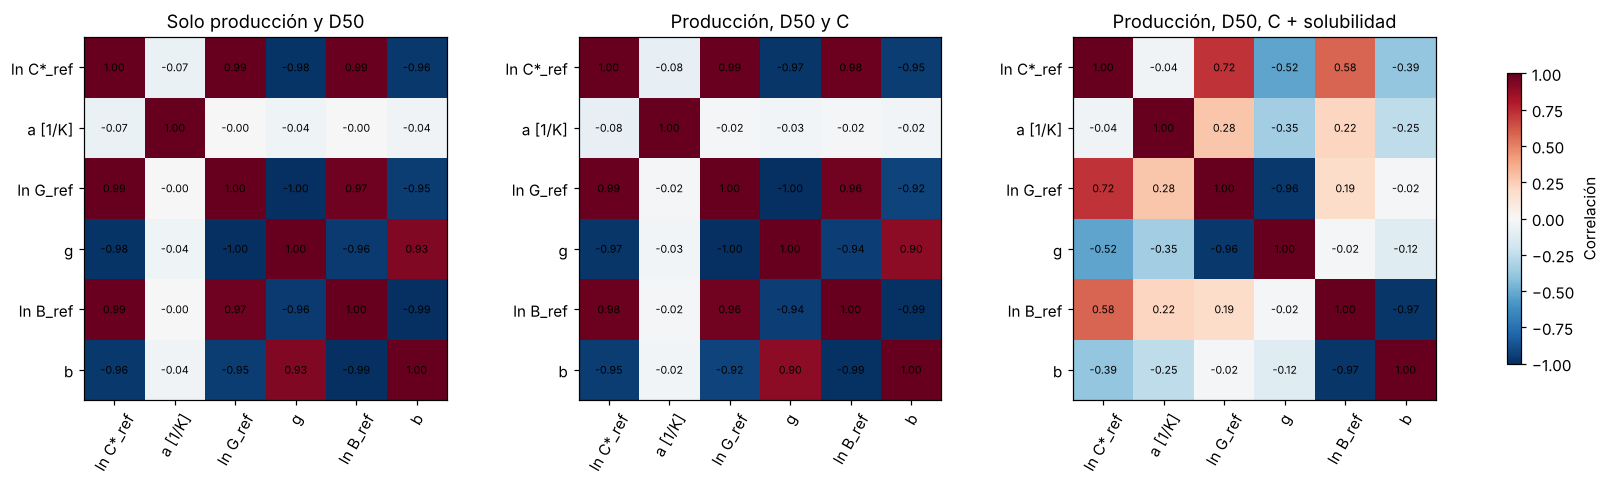

In [5]:
def jacobian(fun, theta, rel_step=1e-4):
    theta = np.asarray(theta, float)
    f0 = fun(theta)
    J = np.empty((f0.size, theta.size))
    for j in range(theta.size):
        h = rel_step * max(abs(theta[j]), 1.0)
        e = np.zeros_like(theta); e[j] = h
        J[:, j] = (fun(theta + e) - fun(theta - e)) / (2 * h)
    return J


def fim_report(J):
    F = J.T @ J
    cov = np.linalg.inv(F)
    sd = np.sqrt(np.diag(cov))
    corr = cov / np.outer(sd, sd)
    return F, cov, sd, corr


plans = {
    'Solo producción y D50': dict(use_solubility=False, columns=(0, 1)),
    'Producción, D50 y C': dict(use_solubility=False, columns=(0, 1, 2)),
    'Producción, D50, C + solubilidad': dict(use_solubility=True, columns=(0, 1, 2)),
}
plan_rows, plan_corr = [], {}
for name, kw in plans.items():
    J0 = jacobian(lambda th: residuals(th, **kw), param_bounds['p0'])
    F0, _, sd0, corr0 = fim_report(J0)
    off = np.abs(corr0[np.triu_indices(6, 1)])
    plan_rows.append({'plan': name, 'cond(F)': np.linalg.cond(F0), 'max |ρ|': off.max(),
                      **{f'sd {l}': v for l, v in zip(THETA_LABELS, sd0)}})
    plan_corr[name] = corr0
display(pd.DataFrame(plan_rows).set_index('plan').T)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
for ax, (name, corr0) in zip(axs, plan_corr.items()):
    im = ax.imshow(corr0, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set(xticks=range(6), yticks=range(6), xticklabels=THETA_LABELS,
           yticklabels=THETA_LABELS, title=name)
    ax.tick_params(axis='x', rotation=60); ax.grid(False)
    for (i, j), v in np.ndenumerate(corr0):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=axs, label='Correlación', shrink=.8)
plt.show()

Lectura esperada: con solo datos del cristalizador, C*_ref, G_ref y B_ref quedan
con |ρ| ≈ 0,999 (no identificables en la práctica). La razón física es que el
cristalizador solo "ve" C = C*(1+σ), y con σ ≈ 2 % un error de 1 % en C* se
compensa cambiando la cinética. Medir C del licor agrega poca información,
porque en estado estacionario producción ≈ Q·(C_f − C) (es redundante). **Los
datos de solubilidad separan termodinámica de cinética**, y desde aquí se usa
ese plan.

## 6. Estimación: PSO global + refinamiento local

1. **PSO** (sesión 2.4): población de partículas dentro de `lb`–`ub`, sin
   derivadas y poco sensible al punto inicial. Se implementa con NumPy (forma
   estándar con inercia y coeficientes cognitivo/social) para no depender de
   `mealpy`; si prefieres `mealpy`, basta con pasar `objective` y los límites.
2. **`least_squares` (Trust Region Reflective)** (sesión 2.2): parte del mejor
   punto del PSO y converge con precisión respetando los límites. Cumple el papel
   de IPOPT en `model_fit`.

PSO: J = 371.7, 1104 evaluaciones, 37 s


least_squares: J = 88.49, estado = 3 (`xtol` termination condition is satisfied.), 81 evaluaciones, 3 s


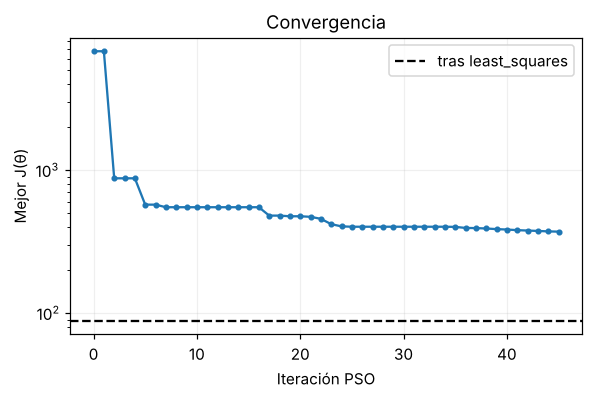

In [6]:
def pso(fun, lb, ub, n_particles=24, n_iter=45, w=(0.9, 0.4), c1=1.6, c2=1.6,
        seed=7, x0=None):
    rng = np.random.default_rng(seed)
    dim = lb.size
    X = lb + rng.random((n_particles, dim)) * (ub - lb)
    if x0 is not None:
        X[0] = x0                                   # incluye la suposición inicial
    V = 0.1 * (ub - lb) * rng.uniform(-1, 1, (n_particles, dim))
    f = np.array([fun(x) for x in X])
    P, fP = X.copy(), f.copy()
    g = P[np.argmin(fP)].copy(); fg = fP.min()
    history = [fg]
    for k in range(n_iter):
        wk = w[0] + (w[1] - w[0]) * k / max(n_iter - 1, 1)   # inercia decreciente
        r1, r2 = rng.random((2, n_particles, dim))
        V = wk * V + c1 * r1 * (P - X) + c2 * r2 * (g - X)
        V = np.clip(V, -0.3 * (ub - lb), 0.3 * (ub - lb))
        X = np.clip(X + V, lb, ub)
        f = np.array([fun(x) for x in X])
        better = f < fP
        P[better], fP[better] = X[better], f[better]
        if fP.min() < fg:
            g, fg = P[np.argmin(fP)].copy(), fP.min()
        history.append(fg)
    return g, fg, np.array(history)


N_EVAL['count'] = 0
t0 = time.time()
theta_pso, J_pso, pso_hist = pso(objective, param_bounds['lb'], param_bounds['ub'],
                                 x0=param_bounds['p0'])
print(f"PSO: J = {J_pso:.4g}, {N_EVAL['count']} evaluaciones, {time.time()-t0:.0f} s")

N_EVAL['count'] = 0
t0 = time.time()
fit = least_squares(residuals, theta_pso, bounds=(param_bounds['lb'], param_bounds['ub']),
                    method='trf', x_scale='jac', diff_step=1e-4, xtol=1e-10, ftol=1e-10)
theta_opt = fit.x
print(f"least_squares: J = {2*fit.cost:.4g}, estado = {fit.status} ({fit.message}), "
      f"{N_EVAL['count']} evaluaciones, {time.time()-t0:.0f} s")
p_opt = theta_to_p(theta_opt)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(pso_hist, marker='.')
ax.axhline(2*fit.cost, ls='--', color='k', label='tras least_squares')
ax.set(xlabel='Iteración PSO', ylabel='Mejor J(θ)', title='Convergencia'); ax.legend()
plt.show()

## 7. Análisis post-regresión: intervalos de confianza y correlaciones

Con el Jacobiano en θ̂:

* s² = J(θ̂)/(n − p): varianza residual. Si los pesos s_ij son correctos,
  s² ≈ 1; si s² ≫ 1, el error real es mayor que el supuesto o el modelo tiene
  falta de ajuste.
* Cov(θ̂) = s²·(SᵀS)⁻¹; IC 95 % = θ̂ ± t(0,975; n−p)·sd.
* Valor t = |θ̂|/sd > t crítico ⇒ el parámetro es significativamente ≠ 0 (para
  g y b), o bien está bien determinado.
* Para los parámetros originales (kG, kB, C*_ref) se propaga la covarianza con
  el método delta: Cov(φ) = A·Cov(θ)·Aᵀ, A = ∂φ/∂θ.

n = 88, p = 6, s² = 1.079, t crítico = 1.989, cond(F) = 7.69e+07


,θ0,θ verdadero,θ̂,sd,IC95 inf,IC95 sup,t valor,en límite
ln C*_ref,5.164786,5.192957,5.191105,0.001949,5.187228,5.194981,2663.621400,False
a [1/K],0.013000,0.010000,0.009944,0.000073,0.009798,0.010090,135.690278,False
ln G_ref,-21.203726,-19.336971,-19.466086,0.122847,-19.710467,-19.221705,158.458450,False
g,1.300000,1.000000,1.206730,0.137213,0.933769,1.479691,8.794551,False
ln B_ref,12.552646,15.201805,14.934559,0.240576,14.455976,15.413141,62.078318,False
b,2.500000,2.000000,2.332224,0.290045,1.755233,2.909216,8.040912,False


,inicial,estimado,IC95 inf,IC95 sup,sd relativa [%],verdadero
parámetro,,,,,,
Cstar_ref_kg_m3,1.750000e+02,1.796669e+02,1.789717e+02,1.803648e+02,0.194889,1.800000e+02
solubility_slope_K_inv,1.300000e-02,9.943830e-03,9.798046e-03,1.008961e-02,0.736972,1.000000e-02
kG_m_s,1.000000e-07,3.946247e-07,1.645874e-07,9.461761e-07,43.959452,2.000000e-07
g,1.300000e+00,1.206730e+00,9.337688e-01,1.479691e+00,11.370677,1.000000e+00
kB_m3_s_inv,5.000000e+09,2.807860e+10,4.241712e+09,1.858702e+11,95.009463,1.000000e+10
b,2.500000e+00,2.332224e+00,1.755233e+00,2.909216e+00,12.436400,2.000000e+00


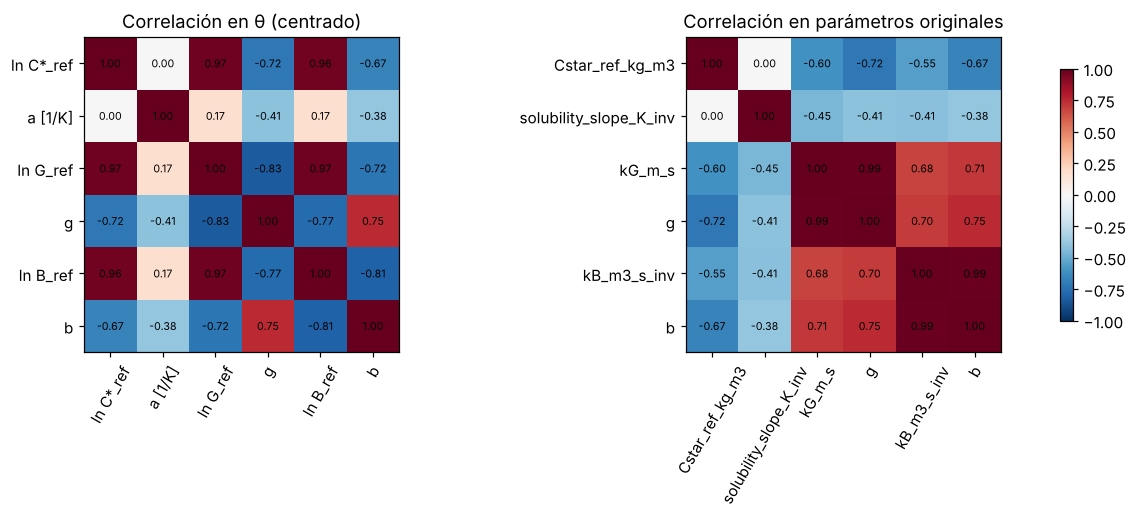

In [7]:
S_opt = jacobian(residuals, theta_opt)
r_opt = residuals(theta_opt)
n_obs, n_par = r_opt.size, theta_opt.size
dof = n_obs - n_par
s2 = float(r_opt @ r_opt / dof)
F_opt = S_opt.T @ S_opt
cov_theta = s2 * np.linalg.inv(F_opt)
sd_theta = np.sqrt(np.diag(cov_theta))
corr_theta = cov_theta / np.outer(sd_theta, sd_theta)
t_crit = stats.t.ppf(0.975, dof)

theta_table = pd.DataFrame({
    'θ0': param_bounds['p0'], 'θ̂': theta_opt, 'sd': sd_theta,
    'IC95 inf': theta_opt - t_crit*sd_theta, 'IC95 sup': theta_opt + t_crit*sd_theta,
    't valor': np.abs(theta_opt)/sd_theta,
    'en límite': np.isclose(theta_opt, param_bounds['lb']) | np.isclose(theta_opt, param_bounds['ub']),
}, index=THETA_LABELS)
if SYNTHETIC:
    theta_table.insert(1, 'θ verdadero', p_to_theta(P_TRUE))
print(f'n = {n_obs}, p = {n_par}, s² = {s2:.3f}, t crítico = {t_crit:.3f}, cond(F) = {np.linalg.cond(F_opt):.3g}')
display(theta_table)

# Método delta hacia los parámetros originales del modelo
ORIG = ['Cstar_ref_kg_m3', 'solubility_slope_K_inv', 'kG_m_s', 'g', 'kB_m3_s_inv', 'b']
def phi(theta):
    p = theta_to_p(theta)
    return np.array([np.log(p[k]) if k in ('Cstar_ref_kg_m3', 'kG_m_s', 'kB_m3_s_inv') else p[k]
                     for k in ORIG])
A = jacobian(phi, theta_opt, 1e-6)
cov_phi = A @ cov_theta @ A.T
sd_phi = np.sqrt(np.diag(cov_phi))
rows = []
for k, v, s in zip(ORIG, phi(theta_opt), sd_phi):
    if k in ('Cstar_ref_kg_m3', 'kG_m_s', 'kB_m3_s_inv'):   # IC simétrico en log ⇒ multiplicativo en el original
        est, lo, hi, rel = np.exp(v), np.exp(v - t_crit*s), np.exp(v + t_crit*s), 100*s
    else:
        est, lo, hi, rel = v, v - t_crit*s, v + t_crit*s, 100*s/abs(v)
    rows.append({'parámetro': k, 'inicial': p_init[k], 'estimado': est,
                 'IC95 inf': lo, 'IC95 sup': hi, 'sd relativa [%]': rel,
                 **({'verdadero': P_TRUE[k]} if SYNTHETIC else {})})
estimates = pd.DataFrame(rows).set_index('parámetro')
display(estimates)

corr_phi = cov_phi / np.outer(sd_phi, sd_phi)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
for ax, M, labels, title in [(axs[0], corr_theta, THETA_LABELS, 'Correlación en θ (centrado)'),
                             (axs[1], corr_phi, ORIG, 'Correlación en parámetros originales')]:
    im = ax.imshow(M, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set(xticks=range(6), yticks=range(6), xticklabels=labels, yticklabels=labels, title=title)
    ax.tick_params(axis='x', rotation=60); ax.grid(False)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=axs, shrink=.8)
plt.show()

La figura derecha muestra por qué se centró la cinética: en coordenadas
originales kG–g y kB–b aparecen casi colineales, aunque la *predicción* esté
igual de bien determinada. Para reportar, usa G_ref, g, B_ref, b junto con
σ_ref, o kG, kB con su correlación.

## 8. Ajuste: gráficos de paridad y solubilidad

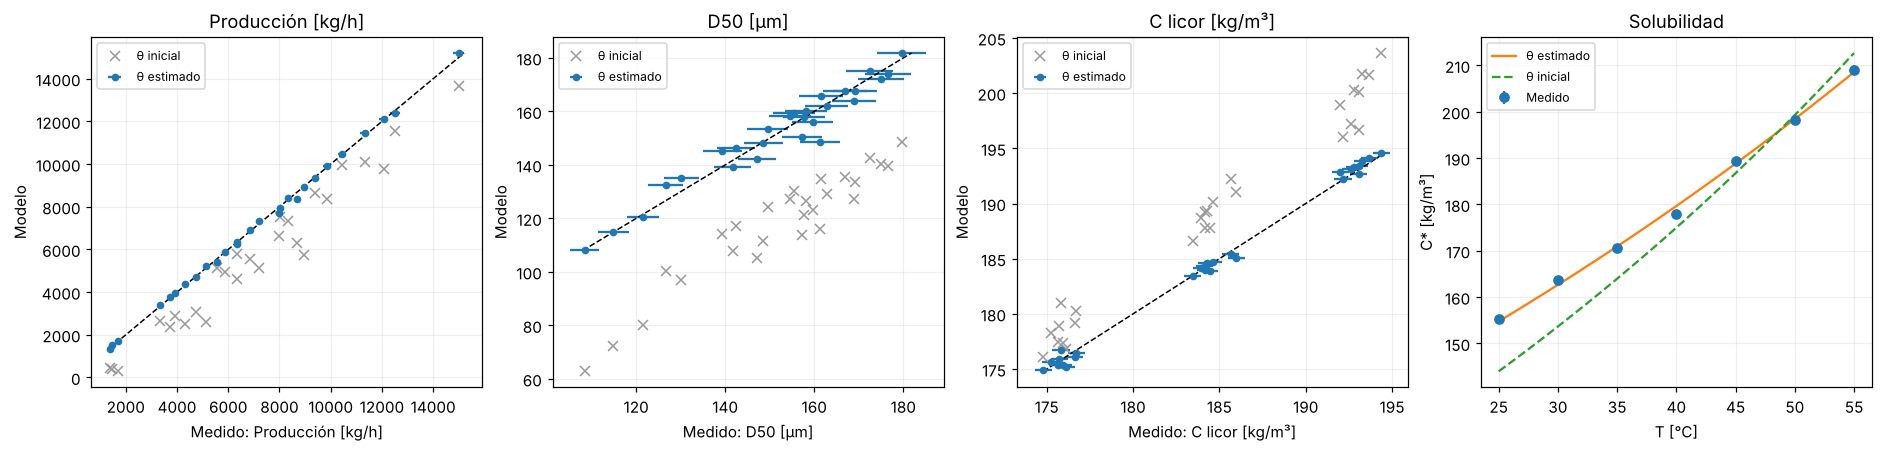

,run,d,T_C,tau_h,crystal_flow_kg_h medido,crystal_flow_kg_h modelo,D50_um medido,D50_um modelo,C_kg_m3 medido,C_kg_m3 modelo
0,R01,0.0,35.0,1.88,14993.229,15205.653,166.969,167.508,175.826,176.684
1,R02,0.0,35.0,2.35,12506.227,12383.622,172.430,175.284,175.733,175.903
2,R03,0.0,35.0,2.82,10426.034,10450.623,179.618,181.836,175.630,175.344
3,R04,0.0,40.0,1.88,12073.242,12124.254,158.072,160.072,185.654,185.462
4,R05,0.0,40.0,2.35,9855.981,9919.782,169.199,167.651,184.625,184.677
5,R06,0.0,40.0,2.82,8348.208,8398.388,176.578,174.033,183.954,184.113
6,R07,0.0,45.0,1.88,8955.808,8915.042,157.244,150.516,194.374,194.604
7,R08,0.0,45.0,2.35,7203.602,7349.891,157.663,157.872,193.282,193.828
8,R09,0.0,45.0,2.82,6336.436,6255.640,168.916,164.048,192.816,193.269


In [8]:
Y_init, Ys_init = simulate_experiments(param_bounds['p0'])
Y_opt, Ys_opt = simulate_experiments(theta_opt)

fig, axs = plt.subplots(1, 4, figsize=(17, 4), constrained_layout=True)
for j, ax in enumerate(axs[:3]):
    ax.errorbar(Y_EXP[:, j], Y_opt[:, j], xerr=SD_EXP[:, j], fmt='o', ms=4, label='θ estimado')
    ax.plot(Y_EXP[:, j], Y_init[:, j], 'x', color='0.6', label='θ inicial')
    lim = [min(Y_EXP[:, j].min(), Y_opt[:, j].min()), max(Y_EXP[:, j].max(), Y_opt[:, j].max())]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set(xlabel=f'Medido: {MEAS_LABELS[j]}', ylabel='Modelo', title=MEAS_LABELS[j])
    ax.legend(fontsize=8)
T_plot = np.linspace(sol_data['T_C'].min(), sol_data['T_C'].max(), 100)
axs[3].errorbar(sol_data['T_C'], YS_EXP, yerr=SDS_EXP, fmt='o', label='Medido')
axs[3].plot(T_plot, [cstar({**p_opt, 'crystallizer_temperature_C': T}) for T in T_plot], label='θ estimado')
axs[3].plot(T_plot, [cstar({**p_init, 'crystallizer_temperature_C': T}) for T in T_plot], '--', label='θ inicial')
axs[3].set(xlabel='T [°C]', ylabel='C* [kg/m³]', title='Solubilidad'); axs[3].legend(fontsize=8)
plt.show()

fit_table = msmpr_data[['run', 'd', 'T_C', 'tau_h']].copy()
for j, k in enumerate(MEASURED):
    fit_table[f'{k} medido'] = Y_EXP[:, j]
    fit_table[f'{k} modelo'] = Y_opt[:, j]
display(fit_table.round(3).head(9))

## 9. Análisis de residuos (sesión 3.4)

Supuestos de mínimos cuadrados: residuos aleatorios, independientes, de media
cero y aproximadamente normales.

* **Durbin–Watson** ≈ 2 ⇒ sin autocorrelación (≪ 2 positiva, ≫ 2 negativa).
  Aquí el "orden" es el de las corridas: un patrón indica tendencia con d, T o τ
  que el modelo no captura.
* **Anderson–Darling**: si el estadístico supera el valor crítico, se rechaza
  normalidad.
* Gráficos residuo vs. condición operacional: buscan estructura (falta de ajuste).

,n,media,sd,Durbin-Watson,A-D estadístico,A-D crítico 5 %,normal (5 %)
serie,,,,,,,
Producción [kg/h],27,0.005,1.115,2.033,0.729,0.729,True
D50 [µm],27,0.002,0.960,1.684,0.336,0.729,True
C licor [kg/m³],27,-0.060,0.984,1.895,0.293,0.729,True
Solubilidad,7,0.087,1.071,1.881,0.338,0.652,True


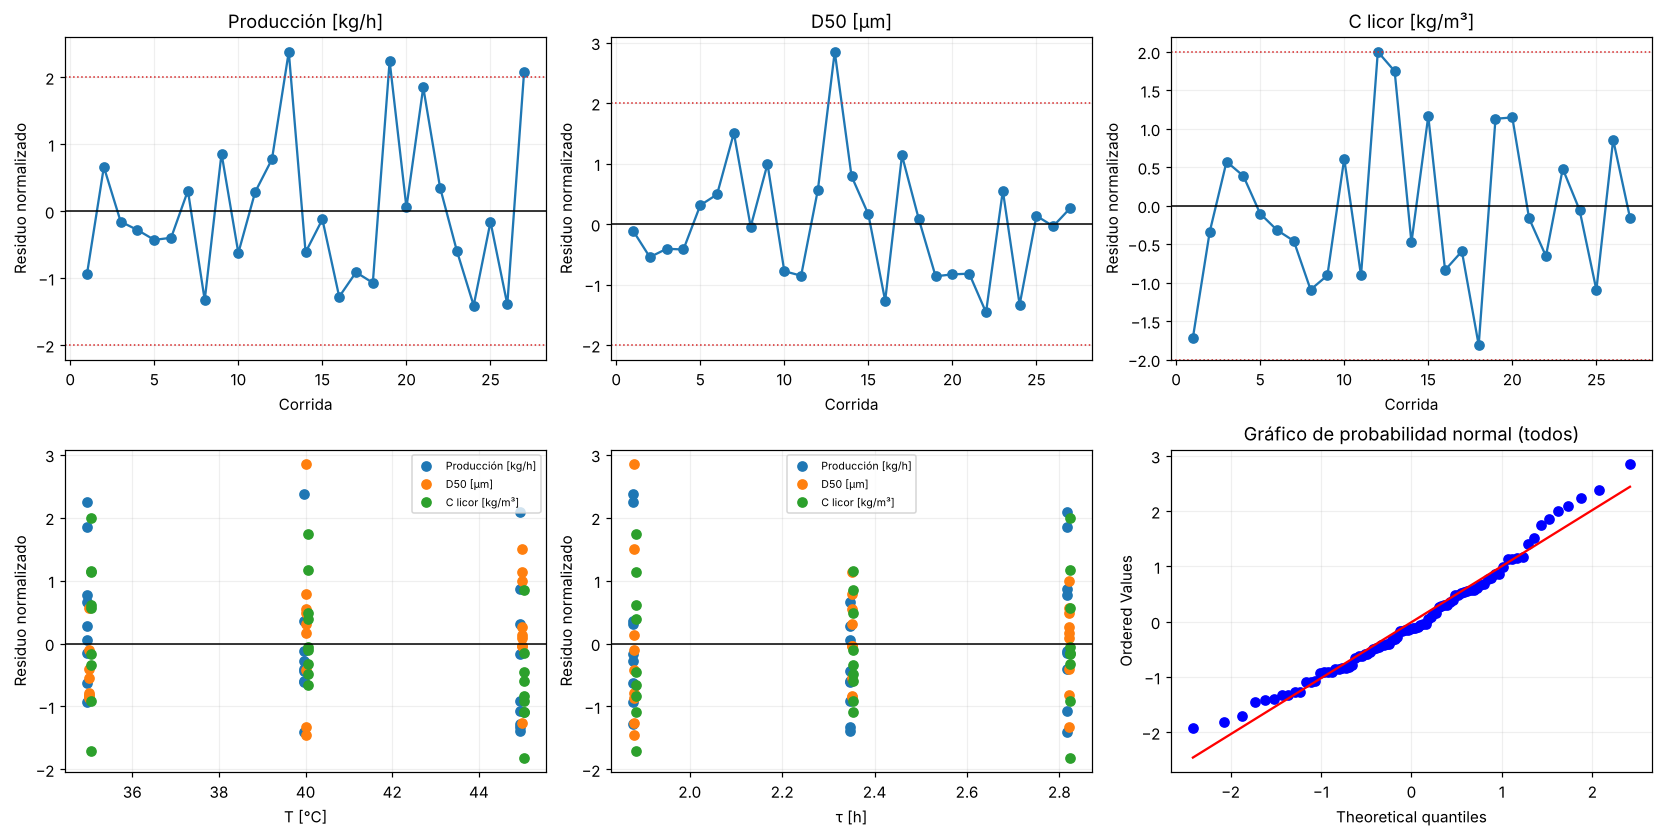

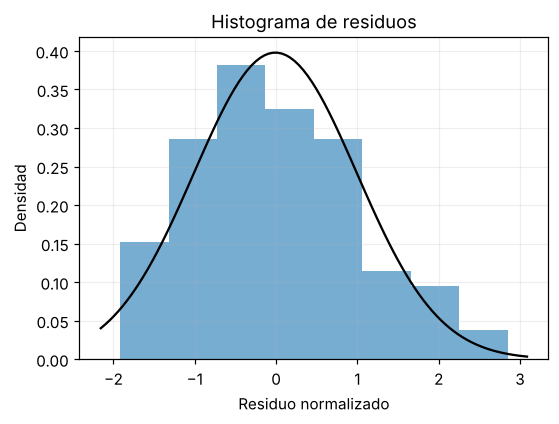

In [9]:
import warnings


def durbin_watson(e):
    e = np.asarray(e)
    return float(np.sum(np.diff(e)**2) / np.sum(e**2))


R_runs = (Y_EXP - Y_opt) / SD_EXP          # residuos normalizados por corrida y salida
R_sol = (YS_EXP - Ys_opt) / SDS_EXP
groups = {**{lab: R_runs[:, j] for j, lab in enumerate(MEAS_LABELS)}, 'Solubilidad': R_sol}
res_rows = []
for name, e in groups.items():
    with warnings.catch_warnings():          # SciPy ≥1.17 avisa cambios de API
        warnings.simplefilter('ignore')
        ad = stats.anderson(e)
    res_rows.append({'serie': name, 'n': e.size, 'media': e.mean(), 'sd': e.std(ddof=1),
                 'Durbin-Watson': durbin_watson(e),
                 'A-D estadístico': ad.statistic, 'A-D crítico 5 %': ad.critical_values[2],
                 'normal (5 %)': ad.statistic < ad.critical_values[2]})
display(pd.DataFrame(res_rows).set_index('serie').round(3))

all_res = np.r_[R_runs.ravel(), R_sol]
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
for j, lab in enumerate(MEAS_LABELS):
    axs[0, j].plot(np.arange(1, len(R_runs)+1), R_runs[:, j], 'o-')
    axs[0, j].axhline(0, color='k', lw=1)
    for lv in (-2, 2):
        axs[0, j].axhline(lv, color='tab:red', ls=':', lw=1)
    axs[0, j].set(xlabel='Corrida', ylabel='Residuo normalizado', title=lab)
for ax, key, lab in zip(axs[1, :2], ['T_C', 'tau_h'], ['T [°C]', 'τ [h]']):
    for j, name in enumerate(MEAS_LABELS):
        ax.plot(msmpr_data[key] + 0.15*(j-1)*(0.3 if key == 'T_C' else 0.02), R_runs[:, j], 'o', label=name)
    ax.axhline(0, color='k', lw=1); ax.set(xlabel=lab, ylabel='Residuo normalizado'); ax.legend(fontsize=7)
stats.probplot(all_res, dist='norm', plot=axs[1, 2])
axs[1, 2].set_title('Gráfico de probabilidad normal (todos)')
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.hist(all_res, bins='auto', density=True, alpha=.6)
x = np.linspace(*ax.get_xlim(), 100)
ax.plot(x, stats.norm.pdf(x, *stats.norm.fit(all_res)), 'k')
ax.set(xlabel='Residuo normalizado', ylabel='Densidad', title='Histograma de residuos')
plt.show()

## 10. Coeficiente de distribución de impureza Kd (paso separado)

Kd no influye en el DPBE, solo en el postprocesamiento de ClO₄. Con θ̂ fijo se
estima Kd con un problema de una variable (mínimos cuadrados ponderados con las
ppm medidas). Esto es una estimación **secuencial**: la incertidumbre de θ̂ no se
propaga a Kd.

In [10]:
base_runs = []
for _, row in msmpr_data.iterrows():
    q = run_parameters(p_opt, row)
    base_runs.append((q, stationary_dpbe(q)))
DPBE_CACHE.clear()
ppm_exp = msmpr_data['impurity_ppm'].to_numpy(float)
ppm_sd = msmpr_data['sd_impurity_ppm'].to_numpy(float)


def ppm_model(Kd):
    return np.array([impurity_postprocess({**q, 'Kd': Kd}, dp)['impurity_ppm'] for q, dp in base_runs])


def ppm_residuals(Kd):
    return (ppm_exp - ppm_model(Kd)) / ppm_sd


kd_fit = minimize_scalar(lambda k: np.sum(ppm_residuals(k)**2), bounds=(1e-4, 0.5), method='bounded',
                         options={'xatol': 1e-10})
Kd_hat = kd_fit.x
h = 1e-6 * Kd_hat
Jk = (ppm_residuals(Kd_hat + h) - ppm_residuals(Kd_hat - h)) / (2*h)
s2k = np.sum(ppm_residuals(Kd_hat)**2) / (ppm_exp.size - 1)
sd_k = np.sqrt(s2k / (Jk @ Jk))
tk = stats.t.ppf(0.975, ppm_exp.size - 1)
print(f'Kd = {Kd_hat:.5f} ± {tk*sd_k:.5f} (IC95 %)' + (f';  verdadero = {P_TRUE["Kd"]}' if SYNTHETIC else ''))

Kd = 0.01006 ± 0.00020 (IC95 %);  verdadero = 0.01


## 11. Verificación numérica en θ̂ y resultado del caso base

Se repite cada corrida con `evaluate` (incluye la comprobación de malla doble y
de balances del notebook original), para asegurar que los parámetros estimados
no llevan a soluciones fuera del dominio o mal resueltas.

In [11]:
p_final = {**p_opt, 'Kd': Kd_hat}
checks = pd.DataFrame([{**{'run': row['run']},
                        **{k: v for k, v in evaluate(run_parameters(p_final, row)).items()
                           if k in ('valid', 'mesh_relative_max', 'tail_mass_fraction', 'phi_s')}}
                       for _, row in msmpr_data.iterrows()])
print(f"Corridas válidas con θ̂: {int(checks['valid'].sum())}/{len(checks)};  "
      f"error máx. de malla = {100*checks['mesh_relative_max'].max():.2f} %")
base_fit = evaluate(p_final)
base_ref = evaluate(BASE)
keys = ('crystal_flow_kg_h', 'D50_um', 'S', 'impurity_ppm')
display(pd.DataFrame({'BASE (notebook sensibilidad)': {k: base_ref[k] for k in keys},
                      'BASE con parámetros estimados': {k: base_fit[k] for k in keys}}))

Corridas válidas con θ̂: 27/27;  error máx. de malla = 0.99 %


,BASE (notebook sensibilidad),BASE con parámetros estimados
crystal_flow_kg_h,6919.865659,6914.807297
D50_um,155.013496,155.961044
S,1.024218,1.026217
impurity_ppm,0.034697,0.034894


## 12. Guardar resultados

`p_final` es un diccionario con la misma estructura que `BASE`: se puede copiar
en el notebook de sensibilidad/Pareto para recalcular el frente con parámetros
estimados.

In [12]:
out_dir = Path('resultados_estimacion')
out_dir.mkdir(exist_ok=True)
with pd.ExcelWriter(out_dir / 'estimacion_parametros.xlsx') as writer:
    estimates.to_excel(writer, sheet_name='parametros_originales')
    theta_table.to_excel(writer, sheet_name='theta_centrado')
    pd.DataFrame(corr_theta, index=THETA_LABELS, columns=THETA_LABELS).to_excel(writer, sheet_name='correlacion')
    fit_table.to_excel(writer, sheet_name='ajuste', index=False)
    pd.DataFrame(res_rows).to_excel(writer, sheet_name='residuos', index=False)
with open(out_dir / 'p_final.json', 'w') as f:
    json.dump({k: v for k, v in p_final.items()}, f, indent=2)
print('Guardado en', out_dir.resolve())
print({k: p_final[k] for k in ORIG + ['Kd']})

Guardado en /tmp/claude-0/-home-claude/cc72ca7b-5487-5041-916b-8dff218bcb15/scratchpad/work/run2/resultados_estimacion
{'Cstar_ref_kg_m3': 179.66689192432844, 'solubility_slope_K_inv': 0.009943829928143761, 'kG_m_s': 3.9462469322509636e-07, 'g': 1.2067299215446916, 'kB_m3_s_inv': 28078603571.79713, 'b': 2.3322242019101314, 'Kd': np.float64(0.01005704821708705)}
